# Random Forest Classifier on Iris Dataset

In this lab, we implement **Random Forest**, an ensemble method that builds multiple decision trees to produce more robust predictions.

#### Core Mechanics from Syllabus:
1. **Data Bagging (Bootstrap Aggregation)**: Each tree is trained on a bootstrap sample (random sampling with replacement) of the training dataset.
2. **Feature Bagging**: At each node split, a random subset of features (typically $\sqrt{d}$) is considered, decorrelating individual trees.
3. **Majority Voting**: Final classification is determined by majority vote across all trees.

### 1. Importing the necessary modules

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

### 2. Loading the built-in Iris dataset directly from scikit-learn

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame
df['species'] = df['target'].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


### 3. Slicing feature matrix X and target vector y

In [3]:
X = df[iris.feature_names]
y = df['target']
X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


### 4. Splitting dataset into Training and Test sets (Stratified)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Training samples: {len(X_train)}, Testing samples: {len(X_test)}")

Training samples: 120, Testing samples: 30


### 5. Training the Random Forest Classifier (100 Trees)

In [5]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    criterion="gini",
    oob_score=True,
    random_state=42
)
rf_model.fit(X_train, y_train)

print("Random Forest Model successfully trained!")
print(f"Out-of-Bag (OOB) Accuracy Score: {rf_model.oob_score_ * 100:.2f}%")

Random Forest Model successfully trained!
Out-of-Bag (OOB) Accuracy Score: 94.17%


### 6. Predicting the Test set results

In [6]:
y_pred_rf = rf_model.predict(X_test)

comparison_df = pd.DataFrame({
    "Actual Class": [iris.target_names[i] for i in y_test],
    "Predicted Class": [iris.target_names[i] for i in y_pred_rf]
})
comparison_df.head(10)

,Actual Class,Predicted Class
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


### 7. Evaluating Model Performance

In [7]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
cm_rf = confusion_matrix(y_test, y_pred_rf)

print(f"Random Forest Test Accuracy: {accuracy_rf * 100:.2f}%")
print()
print("Confusion Matrix:")
print(cm_rf)
print()
print("Classification Report:")
print(classification_report(y_test, y_pred_rf, target_names=iris.target_names))

Random Forest Test Accuracy: 90.00%

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  2  8]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



### 8. Visualizing Feature Importances

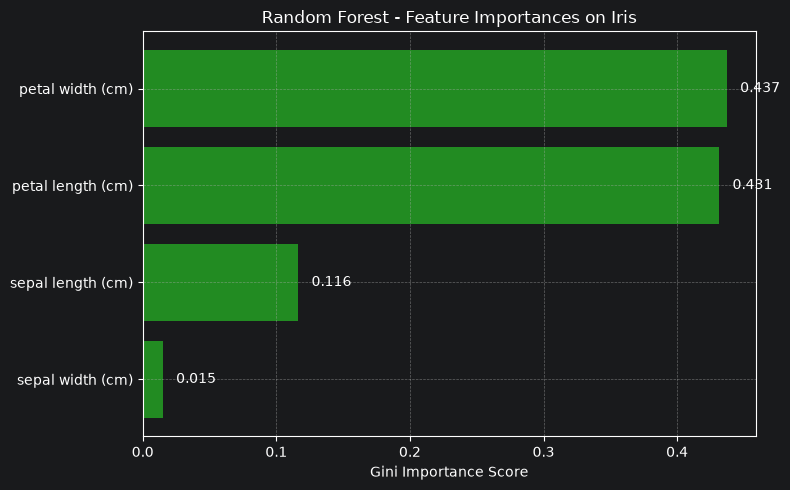

In [8]:
importances = rf_model.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(8, 5))
plt.barh(range(len(importances)), importances[indices], color="forestgreen", align="center")
plt.yticks(range(len(importances)), [iris.feature_names[i] for i in indices])
plt.xlabel("Gini Importance Score")
plt.title("Random Forest - Feature Importances on Iris")
plt.grid(True, linestyle="--", alpha=0.5)

for i, v in enumerate(importances[indices]):
    plt.text(v + 0.01, i, f"{v:.3f}", va="center")

plt.tight_layout()
plt.show()

### 9. Visualizing the Confusion Matrix

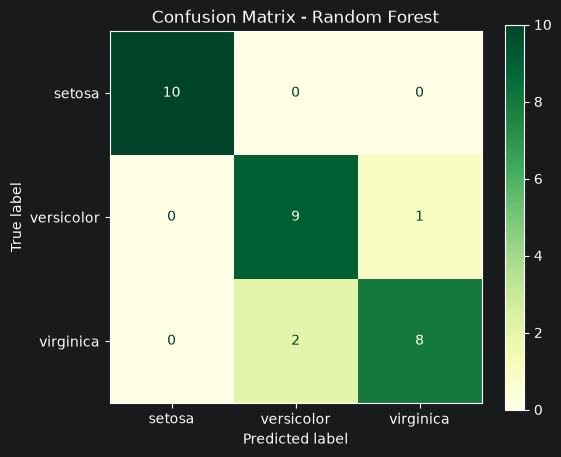

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=iris.target_names)
disp.plot(cmap=plt.cm.YlGn, ax=ax)
plt.title("Confusion Matrix - Random Forest")
plt.grid(False)
plt.show()